# Lab 5 · Generate your own data
**Time:** 60 min  ·  Code: `aiml/generators.py` (also from a terminal: `python -m aiml.generators vfm --n 1000`)

Real datasets are small and fixed. With a generator you control the physics, the noise and the sampling, so you can
ask questions like "how many tests do I need?" or "how much gauge noise can my VFM tolerate?".

| Generator | Physics inside |
|---|---|
| `make_asphaltene_data` | plateau(T, n-alkane) × (1 − exp(−(dilution − onset)/b)), fitted to the 150 clean course tests |
| `make_vfm_data` | inflow `q = PI (Pr − Pwf)` + tubing gradient + Gilbert choke `Pwh = 435 GLR^0.546 q / S^1.89` |
| `make_eor_data` | projects sampled class by class from the course database; optional Taber-rule labels |

In [1]:
# --- setup: works locally and in Google Colab ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("aiml"):
    print("Upload the course kit zip to Colab, then unzip it:  !unzip -q aiml_course_kit.zip && %cd aiml_course_kit")
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
DATA = "../data" if os.path.exists("../data") else "data"

from aiml.generators import make_asphaltene_data, make_vfm_data, make_eor_data, taber_screen
from aiml.data import load_vfm, load_eor, load_asphaltene, VFM_FEATURES, EOR_FEATURES, ASPH_FEATURES, ASPH_TARGET
from aiml.models import regressors, classifiers
from aiml.evaluate import report
from sklearn.metrics import r2_score

## 1 · Synthetic well tests

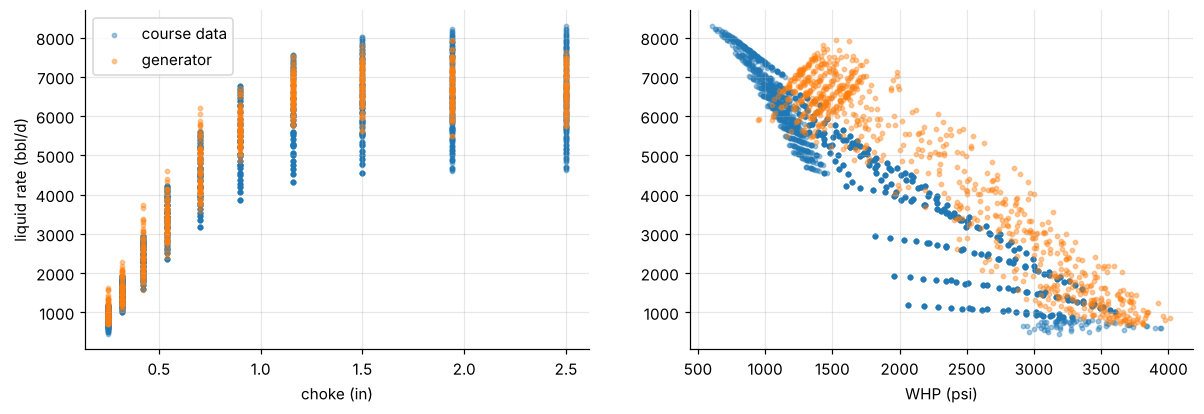

In [2]:
syn = make_vfm_data(n_tests=800, noise=0.01, seed=0)
real = load_vfm()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for d, lab in [(real, "course data"), (syn, "generator")]:
    ax[0].scatter(d.choke_in, d.oil_rate_stb_d + d.water_rate_bbl_d, s=8, alpha=.4, label=lab)
    ax[1].scatter(d.whp_psi, d.oil_rate_stb_d + d.water_rate_bbl_d, s=8, alpha=.4, label=lab)
ax[0].set_xlabel("choke (in)"); ax[1].set_xlabel("WHP (psi)"); ax[0].set_ylabel("liquid rate (bbl/d)"); ax[0].legend(); plt.show()

## 2 · How much gauge noise can a VFM tolerate?
Even with perfect gauges R² stays below 1: the oil rate needs the **water cut**, and no gauge measures it. (The course data has only five water cuts, 0 to 0.8, which makes it easier.)

In [3]:
rows = []
for noise in [0, 0.005, 0.01, 0.02, 0.05]:
    d = make_vfm_data(800, noise=noise, seed=1); t = make_vfm_data(300, noise=noise, seed=2)
    m = regressors()["Extra trees"].fit(d[VFM_FEATURES], d.oil_rate_stb_d)
    rows.append({"gauge noise": noise, "test R2": round(r2_score(t.oil_rate_stb_d, m.predict(t[VFM_FEATURES])), 4)})
pd.DataFrame(rows)

,gauge noise,test R2
0,0.000,0.8826
1,0.005,0.8369
2,0.010,0.7995
3,0.020,0.7397
4,0.050,0.6079


### ✏️ Your turn 1 · how many tests do I need?
With `noise=0.01`, train extra trees on 50, 100, 200, 400 and 800 synthetic tests and test on 300 fresh ones. Plot R² vs number of tests.

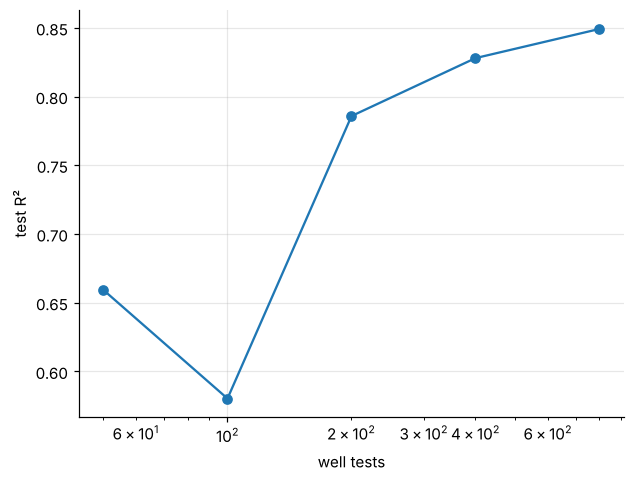

In [4]:
test = make_vfm_data(300, noise=0.01, seed=99); ns = [50, 100, 200, 400, 800]; r = []
for n in ns:
    d = make_vfm_data(n, noise=0.01, seed=n); m = regressors()["Extra trees"].fit(d[VFM_FEATURES], d.oil_rate_stb_d)
    r.append(r2_score(test.oil_rate_stb_d, m.predict(test[VFM_FEATURES])))
plt.semilogx(ns, r, "o-"); plt.xlabel("well tests"); plt.ylabel("test R²"); plt.show()

## 3 · Train on synthetic, test on real (sim-to-real)
A model trained only on the generator, tested on the course well: how far is our physics from the data?

In [5]:
m = regressors()["Extra trees"].fit(syn[VFM_FEATURES], syn.oil_rate_stb_d + syn.water_rate_bbl_d)
report(real.liquid_rate_bbl_d, m.predict(real[VFM_FEATURES]), "synthetic → real (liquid)")

synthetic → real (liquid)    R2 0.940  MAE 434.158  RMSE 524.736  MAPE 12.7%


{'R2': 0.9403274473661415,
 'MAE': 434.15798253968296,
 'RMSE': 524.735822910684,
 'MAPE_%': np.float64(12.662363051372166)}

## 4 · Asphaltene with planted outliers
The generator can plant outliers (here: 6 % of tests multiplied by 1.6–2.5), so you know exactly which ones a method should find.

In [6]:
from aiml.prep import detect_outliers_iqr
d = make_asphaltene_data(noise=0.05, outliers=0.06, outlier_factor=(1.6, 2.5), seed=3)
lo, hi, idx = detect_outliers_iqr(d, ASPH_TARGET)
found = d.index.isin(idx)
print("planted:", d.is_outlier.sum(), " flagged by IQR:", found.sum(), " correctly flagged:", (found & d.is_outlier).sum())

planted: 13  flagged by IQR: 3  correctly flagged: 3


### ✏️ Your turn 2
The IQR rule looks at the target alone, so an outlier on a low curve hides inside the normal range of the high curves.
Flag outliers by their **residual from a model** instead: predict every row with cross-validation (so a row never
predicts itself) and flag rows more than 35 % above the prediction. How many planted outliers do you find now?

In [7]:
from sklearn.model_selection import cross_val_predict, KFold
m = regressors()["Polynomial (deg 2)"]
p = cross_val_predict(m, d[ASPH_FEATURES], d[ASPH_TARGET], cv=KFold(5, shuffle=True, random_state=0))
res = (d[ASPH_TARGET] - p) / np.clip(p, 0.3, None)
flag = res > 0.35
print("planted:", d.is_outlier.sum(), " flagged:", flag.sum(), " correct:", (flag & d.is_outlier).sum())

planted: 13  flagged: 13  correct: 13


## 5 · EOR: rules vs data labels

In [8]:
syn_e = make_eor_data(n=1000, seed=0)
real_e = load_eor()
m = classifiers()["Random forest"].fit(syn_e[EOR_FEATURES], syn_e.eor_method)
print("trained on synthetic, accuracy on the real projects:", round(m.score(real_e[EOR_FEATURES], real_e.eor_method), 3))
print("Taber rules on the real projects:", round((taber_screen(real_e) == real_e.eor_method).mean(), 3))

trained on synthetic, accuracy on the real projects: 0.844
Taber rules on the real projects: 0.771


### ✏️ Your turn 3 (project)
Choose one generator, design a dataset that answers a question you care about (sampling, noise, size), train two
models, and write three sentences: what you asked, what you found, and what it means for a real field study.

## Key ideas
* A generator turns "is my model good?" into controlled experiments: data size, noise, outliers, extrapolation.
* Known truth lets you test methods (outlier detection, splits) before trusting them on field data.
* Sim-to-real gaps show where your physics or your data is incomplete.

In [9]:
# open-ended: see the examples above